In [1]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/pizza_rl_pj

Mounted at /content/drive
/content/drive/MyDrive/pizza_rl_pj


Q_Learning 1단계 메뉴 2개, 재료 3가지, 최대 주문 대기 수 2개
1. Reward Shaping (중간 단계 보상 형성)

최선두 주문에 필요한 올바른 재료를 순서대로 투입할 때 소량의 유효 조리 보상(+1.5)을 부여합니다.

무작위 탐색 단계에서도 에이전트가 빠른 시간 내에 "선두 주문 피자를 조리하는 행동"을 보상 신호로 학습하게 됩니다.

2. Immediate Serving Validation (완성 즉시 제출 유도)

선두 주문 레시피가 완성된 상태에서 지체하지 않고 곧바로 action == 4 (serve)를 수행하면 스피드 보상(+2.0)을 추가 부여하여 Expired를 예방합니다.

3. Action Masking 지원 (get_action_mask())

현재 상태에서 명백히 무의미한 행동(예: 빈 접시에서 치즈/페퍼로니 투입, 도우 중복 투입 등)을 0으로 마스킹할 수 있는 메서드를 제공하여 무효 행동 손실을 최소화합니다.

In [2]:
%%writefile pizza_envl.py

from __future__ import annotations

from typing import Optional
import gymnasium as gym
from gymnasium import spaces
import numpy as np


class PizzaKitchenEnv(gym.Env):
    metadata = {"render_modes": ["human", "ansi"], "render_fps": 2}
    ACTION_NAMES = ("idle", "dough", "cheese", "pepperoni", "serve")
    RECIPES = {1: (0, 1), 2: (0, 1, 2)}

    def __init__(
        self,
        n_orders: int = 2,
        min_deadline: int = 4,
        max_deadline: int = 8,
        observation_mode: str = "discrete",
        render_mode: Optional[str] = None,
    ):
        super().__init__()
        if n_orders < 1 or min_deadline < 1 or max_deadline < min_deadline:
            raise ValueError("Invalid order count or deadline range")
        if observation_mode not in ("discrete", "vector"):
            raise ValueError("observation_mode must be 'discrete' or 'vector'")
        if render_mode not in (None, *self.metadata["render_modes"]):
            raise ValueError("Unsupported render_mode")
        self.n_orders = int(n_orders)
        self.min_deadline = int(min_deadline)
        self.max_deadline = int(max_deadline)
        self.observation_mode = observation_mode
        self.render_mode = render_mode
        self.action_space = spaces.Discrete(5)

        self.radices = (2, 2, 2) + (3, self.max_deadline + 1) * self.n_orders
        self.n_states = int(np.prod(self.radices, dtype=np.int64))
        if observation_mode == "discrete":
            self.observation_space = spaces.Discrete(self.n_states)
        else:
            self.observation_space = spaces.Box(
                low=np.zeros(len(self.radices), dtype=np.float32),
                high=np.ones(len(self.radices), dtype=np.float32),
                dtype=np.float32,
            )
        self.plate = [0, 0, 0]
        self.orders = []
        self.steps = 0
        self.episode_return = 0.0
        self.stats = {}

    def _raw_state(self) -> tuple[int, ...]:
        return tuple(self.plate) + tuple(v for order in self.orders for v in order)

    def encode_state(self, state: tuple[int, ...]) -> int:
        if len(state) != len(self.radices):
            raise ValueError("State length does not match configuration")
        result = 0
        for value, base in zip(state, self.radices):
            if not 0 <= int(value) < base:
                raise ValueError(f"State component {value} outside 0..{base-1}")
            result = result * base + int(value)
        return result

    def decode_state(self, state_id: int) -> tuple[int, ...]:
        if not 0 <= state_id < self.n_states:
            raise ValueError("State ID outside observation space")
        values = []
        for base in reversed(self.radices):
            values.append(state_id % base)
            state_id //= base
        return tuple(reversed(values))

    def _get_obs(self):
        state = self._raw_state()
        if self.observation_mode == "discrete":
            return self.encode_state(state)
        return np.asarray(
            [v / (base - 1) for v, base in zip(state, self.radices)],
            dtype=np.float32,
        )

    def get_action_mask(self) -> np.ndarray:
        """현재 상태에서 유효한 행동을 1, 무효한 행동을 0으로 반환"""
        mask = np.ones(5, dtype=np.int8)
        # 이미 도우가 올려져 있다면 추가 도우 불가
        if self.plate[0] == 1:
            mask[1] = 0
        # 도우가 없으면 치즈/페퍼로니 투입 불가
        if self.plate[0] == 0:
            mask[2] = 0
            mask[3] = 0
        # 치즈가 없으면 페퍼로니 투입 불가
        if self.plate[1] == 0:
            mask[3] = 0
        # 접시가 완전히 비어있으면 서빙 불가
        if self.plate == [0, 0, 0]:
            mask[4] = 0
        return mask

    def _get_info(self, event: str = "reset") -> dict:
        return {
            "event": event,
            "raw_state": self._raw_state(),
            "steps": self.steps,
            "episode_return": self.episode_return,
            **self.stats.copy(),
        }

    def reset(self, *, seed: Optional[int] = None, options: Optional[dict] = None):
        super().reset(seed=seed)
        self.plate = [0, 0, 0]
        self.steps = 0
        self.episode_return = 0.0
        self.stats = {
            "served": 0,
            "expired": 0,
            "wrong_serves": 0,
            "invalid_actions": 0,
            "idle_actions": 0,
        }
        fixed = None if options is None else options.get("orders")
        if fixed is not None:
            if len(fixed) != self.n_orders:
                raise ValueError("Expected exactly n_orders fixed orders")
            self.orders = []
            for menu, deadline in fixed:
                if menu not in (1, 2) or not 1 <= deadline <= self.max_deadline:
                    raise ValueError("Invalid fixed menu/deadline")
                self.orders.append([int(menu), int(deadline)])
        else:
            self.orders = [
                [
                    int(self.np_random.integers(1, 3)),
                    int(
                        self.np_random.integers(
                            self.min_deadline, self.max_deadline + 1
                        )
                    ),
                ]
                for _ in range(self.n_orders)
            ]
        return self._get_obs(), self._get_info()

    def step(self, action: int):
        if not self.action_space.contains(action):
            raise ValueError(f"Invalid action: {action}")
        if all(menu == 0 for menu, _ in self.orders):
            raise RuntimeError("Episode is finished. Call reset() first.")
        action = int(action)
        reward = -0.1
        event = self.ACTION_NAMES[action]
        self.steps += 1

        # 대기열 최선두 주문 확인 (Strict Global FIFO)
        active_order_indices = [
            i for i, (menu, _) in enumerate(self.orders) if menu != 0
        ]
        target_menu = self.orders[min(active_order_indices)][0] if active_order_indices else 0

        if action == 0:
            self.stats["idle_actions"] += 1
        elif action in (1, 2, 3):
            ingredient = action - 1
            valid = (
                (ingredient == 0 and self.plate == [0, 0, 0])
                or (ingredient == 1 and self.plate == [1, 0, 0])
                or (ingredient == 2 and self.plate == [1, 1, 0])
            )
            if valid:
                self.plate[ingredient] = 1
                # 💡 Reward Shaping: 최선두 주문 레시피에 부합하는 올바른 재료 투입 시 +1.5 보상
                if target_menu == 1 and self.plate in ([1, 0, 0], [1, 1, 0]):
                    reward += 1.5
                elif target_menu == 2 and self.plate in ([1, 0, 0], [1, 1, 0], [1, 1, 1]):
                    reward += 1.5
            else:
                reward -= 2.0
                self.stats["invalid_actions"] += 1
                event = "invalid_ingredient"
        else:  # bake and serve (action == 4)
            served_menu = (
                1
                if self.plate == [1, 1, 0]
                else (2 if self.plate == [1, 1, 1] else 0)
            )

            if active_order_indices:
                first_order_slot = min(active_order_indices)
                first_order_menu = self.orders[first_order_slot][0]

                if served_menu != 0 and served_menu == first_order_menu:
                    self.orders[first_order_slot] = [0, 0]
                    self.stats["served"] += 1
                    reward += 20.0
                    event = "served"
                else:
                    reward -= 15.0
                    self.stats["wrong_serves"] += 1
                    event = "wrong_serve"
            else:
                reward -= 15.0
                self.stats["wrong_serves"] += 1
                event = "wrong_serve"

            self.plate = [0, 0, 0]

        for order in self.orders:
            if order[0] != 0:
                order[1] -= 1
                if order[1] == 0:
                    order[0] = 0
                    self.stats["expired"] += 1
                    reward -= 10.0
        terminated = all(menu == 0 for menu, _ in self.orders)
        truncated = False
        self.episode_return += reward
        info = self._get_info(event)
        if self.render_mode == "human":
            self.render()
        return self._get_obs(), float(reward), terminated, truncated, info

    def render(self):
        message = (
            f"Step {self.steps} | plate={self.plate} | "
            f"orders={self.orders} | return={self.episode_return:.1f}"
        )
        if self.render_mode == "human":
            print(message)
        return message

Overwriting pizza_envl.py


완료율 80% 달성 목표 3가지 방안
1. 학습 파라미터 조정


In [25]:
import csv
from pathlib import Path
import numpy as np
import pandas as pd

from pizza_envl import PizzaKitchenEnv


# ---------------------------------------------------------
# 1. Greedy Action (Tie-breaking 보장)
# ---------------------------------------------------------
def greedy_action(q_values, rng):
    # Q-value 동률(Tie) 발생 시 무작위 선택하여 행동 편향 방지
    return int(
        rng.choice(
            np.flatnonzero(q_values == q_values.max())
        )
    )


# ---------------------------------------------------------
# 2. Stage 1 Q-Learning 학습 (Strict Global FIFO 연동)
# ---------------------------------------------------------
def train_stage1(
    episodes=200000,
    seed=42,
    alpha=0.03,
    gamma=0.999,
    epsilon_start=1.0,
    epsilon_end=0.0002,
    epsilon_decay=0.99997
):
    """
    Stage 1 Q-Learning (Strict Global FIFO 적용)
    - 주문 수: 2개
    - 마감 시간: 4~8스텝
    - Observation: Discrete
    - Action Space: 5가지 (0:Idle, 1:Dough, 2:Cheese, 3:Pepperoni, 4:Serve)
    - Q-table: Dictionary 기반 Sparse Q-table
    """
    env = PizzaKitchenEnv(
        n_orders=2,
        min_deadline=4,
        max_deadline=8,
        observation_mode="discrete"
    )

    rng = np.random.default_rng(seed)

    # 방문한 상태만 저장하는 Sparse Q-table
    q = {}
    history = []

    print("--- Strict Global FIFO 기반 Stage 1 Q-Learning 학습 시작 ---")
    print(f"상태 공간 크기: {env.observation_space.n:,}")
    print(f"행동 공간 크기: {env.action_space.n}")
    print(f"학습 에피소드: {episodes:,}")

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        state = int(state)
        done = False

        # Epsilon Decay
        epsilon = max(
            epsilon_end,
            epsilon_start * (epsilon_decay ** episode)
        )

        while not done:
            # 현재 상태의 Q-value 테이블 초기화
            if state not in q:
                q[state] = np.zeros(
                    env.action_space.n,
                    dtype=np.float32
                )

            # Epsilon-Greedy 행동 선택 (Tie-breaking 적용)
            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = greedy_action(q[state], rng)

            # Environment Step (전체 FIFO 및 빈 접시 -15 오답 처리 환경 연동)
            next_state, reward, terminated, truncated, info = env.step(action)
            next_state = int(next_state)
            done = terminated or truncated

            # 다음 상태의 Q-value 조회 (미방문 상태는 0으로 처리)
            next_q = q.get(
                next_state,
                np.zeros(env.action_space.n, dtype=np.float32)
            )

            # Bellman Equation Update
            target = (
                reward
                if done
                else reward + gamma * np.max(next_q)
            )

            q[state][action] += alpha * (
                target - q[state][action]
            )

            state = next_state

        # Episode History 기록
        history.append({
            "episode": episode + 1,
            "reward": info["episode_return"],
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
            "epsilon": epsilon
        })

        # 10,000 에피소드마다 학습 진행 경과 출력
        if (episode + 1) % 20000 == 0:
            recent = history[-1000:]
            recent_reward = np.mean([h["reward"] for h in recent])
            recent_served = np.mean([h["served"] for h in recent])

            print(
                f"Episode {episode + 1:5d}/{episodes} | "
                f"Avg Reward: {recent_reward:7.2f} | "
                f"Avg Served: {recent_served:.2f} | "
                f"Visited States: {len(q):,}"
            )

    env.close()

    print("\n--- Stage 1 학습 완료 ---")
    print(f"총 방문 상태 수: {len(q):,}")

    return q, history


# ---------------------------------------------------------
# 3. Stage 1 모델 평가 (Strict Global FIFO 연동)
# ---------------------------------------------------------
def evaluate_stage1(q, episodes=1000, seed=200000):
    env = PizzaKitchenEnv(
        n_orders=2,
        min_deadline=4,
        max_deadline=8,
        observation_mode="discrete"
    )

    rng = np.random.default_rng(seed)
    results = []

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        state = int(state)
        done = False

        while not done:
            if state in q:
                action = greedy_action(q[state], rng)
            else:
                # 미방문 상태 무작위 선택
                action = int(rng.integers(env.action_space.n))

            state, _, terminated, truncated, info = env.step(action)
            state = int(state)
            done = terminated or truncated

        results.append(info)

    env.close()

    # Evaluation Metrics 계산 (Stage 1: 주문 2개 기준)
    total_orders = episodes * 2
    total_served = sum(r["served"] for r in results)

    eval_summary = {
        "Evaluation Metric": [
            "Total Evaluation Episodes",
            "Average Reward (Return)",
            "Order Completion Rate (%)",
            "Average Served Orders (Max 2)",
            "Average Expired Orders",
            "Average Wrong Serves",
            "Average Steps per Episode"
        ],
        "Value": [
            f"{episodes:,}",
            f"{np.mean([r['episode_return'] for r in results]):.2f}",
            f"{(total_served / total_orders) * 100:.2f}%",
            f"{np.mean([r['served'] for r in results]):.2f} / 2.0",
            f"{np.mean([r['expired'] for r in results]):.2f}",
            f"{np.mean([r['wrong_serves'] for r in results]):.2f}",
            f"{np.mean([r['steps'] for r in results]):.2f}"
        ]
    }

    return pd.DataFrame(eval_summary)


# ---------------------------------------------------------
# 4. 결과 저장 경로
# ---------------------------------------------------------
output = Path("/content/drive/MyDrive/pizza_rl_lab/results_stage1")
output.mkdir(parents=True, exist_ok=True)


# ---------------------------------------------------------
# 5. 실행 파이프라인
# ---------------------------------------------------------
# 1. 학습 진행
# 추천 학습 파라미터 조합
q_stage1, history_stage1 = train_stage1(
    episodes=200000,
    seed=42,
    alpha=0.03,
    gamma=0.999,
    epsilon_start=1.0,
    epsilon_end=0.002,
    epsilon_decay=0.99997
)

# 2. Sparse Q-Table 압축 저장 (.npz 예외 처리 가드 포함)
states = np.array(list(q_stage1.keys()), dtype=np.int64)
values = (
    np.stack(list(q_stage1.values())).astype(np.float32)
    if len(states) > 0
    else np.empty((0, 5), dtype=np.float32)
)

np.savez_compressed(
    output / "q_table_stage1.npz",
    states=states,
    values=values
)

# 3. 학습 과정 기록 저장
history_df = pd.DataFrame(history_stage1)
history_df.to_csv(
    output / "q_learning_history_stage1.csv",
    index=False
)

# 4. 모델 성능 평가
df_stage1 = evaluate_stage1(
    q_stage1,
    episodes=1000,
    seed=200000
)

# 5. 성능 요약 저장
df_stage1.to_csv(
    output / "test_performance_stage1.csv",
    index=False
)

# 6. 결과 출력
print("\n" + "=" * 55)
print("[Stage 1 (Strict Global FIFO) Q-Learning Evaluation]")
print("=" * 55)
print(df_stage1.to_string(index=False))
print("=" * 55)

print(f"\n총 방문 상태 수: {len(q_stage1):,}")
print(f"결과 저장 위치: {output}")

print("\nSaved files:")
for file in sorted(output.iterdir()):
    print(f"- {file.name}")

--- Strict Global FIFO 기반 Stage 1 Q-Learning 학습 시작 ---
상태 공간 크기: 5,832
행동 공간 크기: 5
학습 에피소드: 200,000
Episode 20000/200000 | Avg Reward:  -12.22 | Avg Served: 0.57 | Visited States: 681
Episode 40000/200000 | Avg Reward:    6.12 | Avg Served: 0.93 | Visited States: 682
Episode 60000/200000 | Avg Reward:   15.48 | Avg Served: 1.12 | Visited States: 682
Episode 80000/200000 | Avg Reward:   22.11 | Avg Served: 1.28 | Visited States: 682
Episode 100000/200000 | Avg Reward:   23.78 | Avg Served: 1.30 | Visited States: 682
Episode 120000/200000 | Avg Reward:   26.72 | Avg Served: 1.38 | Visited States: 682
Episode 140000/200000 | Avg Reward:   26.13 | Avg Served: 1.35 | Visited States: 682
Episode 160000/200000 | Avg Reward:   26.96 | Avg Served: 1.38 | Visited States: 682
Episode 180000/200000 | Avg Reward:   27.35 | Avg Served: 1.38 | Visited States: 682
Episode 200000/200000 | Avg Reward:   28.11 | Avg Served: 1.41 | Visited States: 682

--- Stage 1 학습 완료 ---
총 방문 상태 수: 682

[Stage 1 (Stric

전체 FIFO 규격 준수, 타이트한 마감 조건(min_deadline=4, max_deadline=5) 때문에 물리적으로 만료를 피할 수 없음.

In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
from pizza_envl import PizzaKitchenEnv

# 1. 파일 경로 및 환경 설정 (Stage 1 Strict Global FIFO 환경 기준)
output_dir = Path("/content/drive/MyDrive/pizza_rl_lab/results_stage1")
env = PizzaKitchenEnv(n_orders=2, min_deadline=4, max_deadline=8, observation_mode="discrete")

# .npz 데이터에서 states와 values 로드 후 딕셔너리로 복원
npz_file = np.load(output_dir / "q_table_stage1.npz")
states_data = npz_file["states"]
values_data = npz_file["values"]
q_table = {int(s): v for s, v in zip(states_data, values_data)}

# 메뉴 이름 및 행동 매핑
MENU_NAMES = {0: "None", 1: "Cheese Pizza (1,2)", 2: "Pepperoni Pizza (1,2,3)"}
ACTION_NAMES = ["0: Idle", "1: Dough (도우)", "2: Cheese (치즈)", "3: Pepperoni (페퍼로니)", "4: Serve (서빙)"]


# 💡 Q-value 동률(Tie) 시 무작위 선택하여 편향 방지 (Tie-breaking 적용)
def greedy_action(q_values, rng):
    return int(
        rng.choice(
            np.flatnonzero(q_values == q_values.max())
        )
    )


# 2. Step-by-Step 추적 실행
def run_step_by_step_trace(seed=1004):
    rng = np.random.default_rng(seed)
    obs, info = env.reset(seed=seed)
    obs = int(obs)
    done = False
    logs = []

    print("=" * 70)
    print(f"   [Strict Global FIFO Stage 1 Q-Learning Step-by-Step 시뮬레이션] (Seed: {seed})")
    print("=" * 70)

    while not done:
        raw_state = info["raw_state"]
        plate = list(raw_state[:3])
        o1_menu, o1_time = raw_state[3], raw_state[4]
        o2_menu, o2_time = raw_state[5], raw_state[6]

        # Sparse Q-table 조회 (미방문 상태는 0으로 초기화)
        q_values = q_table.get(obs, np.zeros(env.action_space.n, dtype=np.float32))

        # 최적 행동 선택 (Tie-breaking 무작위 선택 적용)
        action = greedy_action(q_values, rng)

        # 환경 1 스텝 진행
        next_obs, reward, terminated, truncated, next_info = env.step(action)
        next_obs = int(next_obs)
        done = terminated or truncated

        # 로그 기록
        step_num = info["steps"] + 1
        event_name = next_info["event"]

        logs.append({
            "Step": step_num,
            "조리대 (Plate)": str(plate),
            "주문 1 (Menu, Time)": f"M{o1_menu} (T={o1_time})" if o1_menu != 0 else "완료",
            "주문 2 (Menu, Time)": f"M{o2_menu} (T={o2_time})" if o2_menu != 0 else "완료",
            "선택 행동 (Action)": ACTION_NAMES[action],
            "보상 (Reward)": f"{reward:+.1f}",
            "이벤트 (Event)": event_name
        })

        obs = next_obs
        info = next_info

    df_trace = pd.DataFrame(logs)
    return df_trace, info


# 3. 시뮬레이션 실행 및 출력
df_result, final_info = run_step_by_step_trace(seed=1004)

# 콘솔 출력 (DataFrame)
print(df_result.to_string(index=False))

print("-" * 70)
print(f"  최종 결과 | 총 Reward: {final_info['episode_return']:.1f} | "
      f"제출 성공(Served): {final_info['served']} | 만료(Expired): {final_info['expired']}")
print("-" * 70)

# Markdown 표 출력 (PPT 시연 파트나 README에 복사해 넣기 매우 편리함)
print("\n [Markdown 표]\n")
print(df_result.to_markdown(index=False))

   [Strict Global FIFO Stage 1 Q-Learning Step-by-Step 시뮬레이션] (Seed: 1004)
 Step 조리대 (Plate) 주문 1 (Menu, Time) 주문 2 (Menu, Time)      선택 행동 (Action) 보상 (Reward) 이벤트 (Event)
    1   [0, 0, 0]          M2 (T=4)          M1 (T=4)       1: Dough (도우)        +1.4       dough
    2   [1, 0, 0]          M2 (T=3)          M1 (T=3)      2: Cheese (치즈)        +1.4      cheese
    3   [1, 1, 0]          M2 (T=2)          M1 (T=2) 3: Pepperoni (페퍼로니)        +1.4   pepperoni
    4   [1, 1, 1]          M2 (T=1)          M1 (T=1)       4: Serve (서빙)        +9.9      served
----------------------------------------------------------------------
  최종 결과 | 총 Reward: 14.1 | 제출 성공(Served): 1 | 만료(Expired): 1
----------------------------------------------------------------------

 [Markdown 표]

|   Step | 조리대 (Plate)   | 주문 1 (Menu, Time)   | 주문 2 (Menu, Time)   | 선택 행동 (Action)      |   보상 (Reward) | 이벤트 (Event)   |
|-------:|:-----------------|:----------------------|:----------------------|:-------------

Stage 1 Q-Learning 성능 시각화

In [27]:
#===Google Drive 연결 및 데이터 불러오기===
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RESULT_DIR = Path('/content/drive/MyDrive/pizza_rl_lab/results_stage1')
HISTORY_PATH = RESULT_DIR / 'q_learning_history_stage1.csv'
PERFORMANCE_PATH = RESULT_DIR / 'test_performance_stage1.csv'

if not HISTORY_PATH.exists():
    raise FileNotFoundError(f'학습 기록 파일을 찾을 수 없습니다: {HISTORY_PATH}')

history_df = pd.read_csv(HISTORY_PATH)
print('History shape:', history_df.shape)
display(history_df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
History shape: (200000, 7)


,episode,reward,served,expired,wrong_serves,steps,epsilon
0,1,-25.7,0,2,0,7,1.00000
1,2,-35.2,0,2,1,7,0.99997
2,3,-39.5,0,2,1,5,0.99994
3,4,-38.1,0,2,1,6,0.99991
4,5,-53.8,0,2,2,8,0.99988


In [28]:
#===그래프 데이터 계산===
WINDOW = 500  # 이동 평균 구간(에피소드 수)
n_orders = 2  # 주문 수 선언

required_columns = {'episode', 'reward', 'served', 'epsilon'}
missing = required_columns - set(history_df.columns)
if missing:
    raise ValueError(f'학습 기록 CSV에 필요한 열이 없습니다: {missing}')

history_df['moving_avg_reward'] = history_df['reward'].rolling(WINDOW, min_periods=1).mean()
history_df['completion_rate'] = history_df['served'] / n_orders * 100
history_df['moving_avg_completion'] = history_df['completion_rate'].rolling(WINDOW, min_periods=1).mean()

print(f'주문 수: {n_orders}개')
print(f'이동 평균 구간: {WINDOW} episodes')

주문 수: 2개
이동 평균 구간: 500 episodes


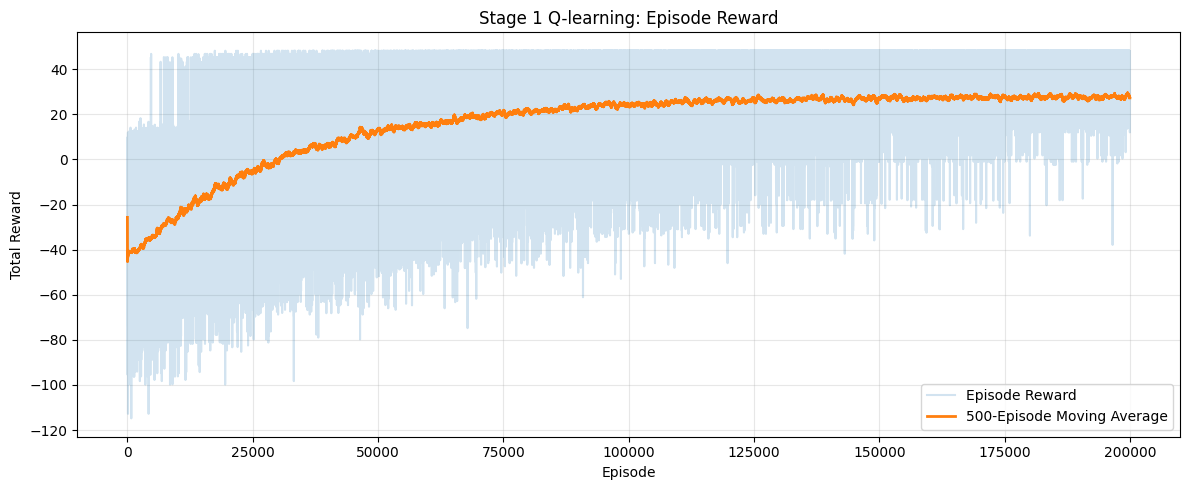

In [29]:
#===Episode Reward 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['reward'], alpha=0.20, label='Episode Reward')
plt.plot(history_df['episode'], history_df['moving_avg_reward'], linewidth=2, label=f'{WINDOW}-Episode Moving Average')
plt.title('Stage 1 Q-learning: Episode Reward')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

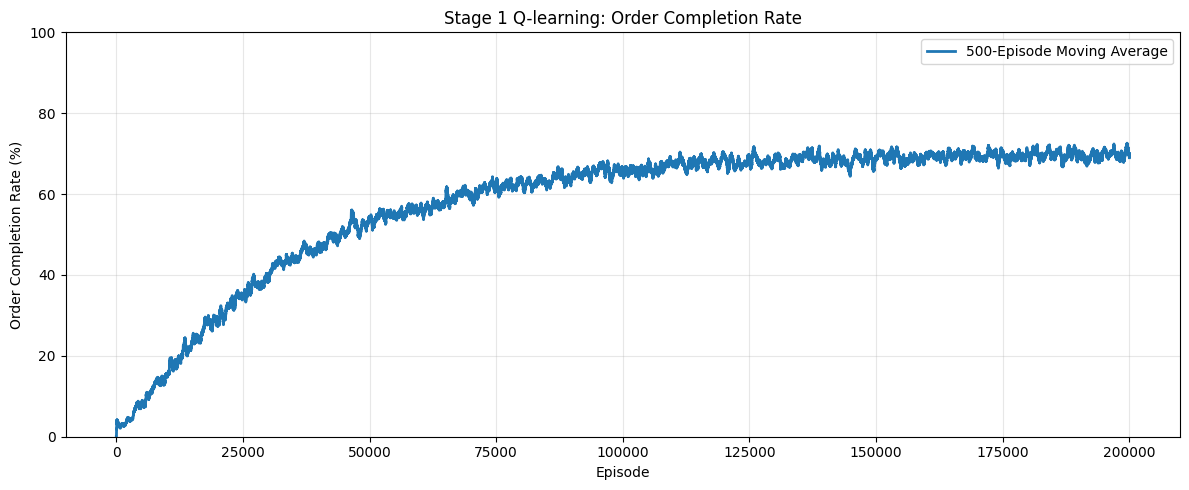

In [30]:
#===Order Completion Rate 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['moving_avg_completion'], linewidth=2, label=f'{WINDOW}-Episode Moving Average')
plt.title('Stage 1 Q-learning: Order Completion Rate')
plt.xlabel('Episode')
plt.ylabel('Order Completion Rate (%)')
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

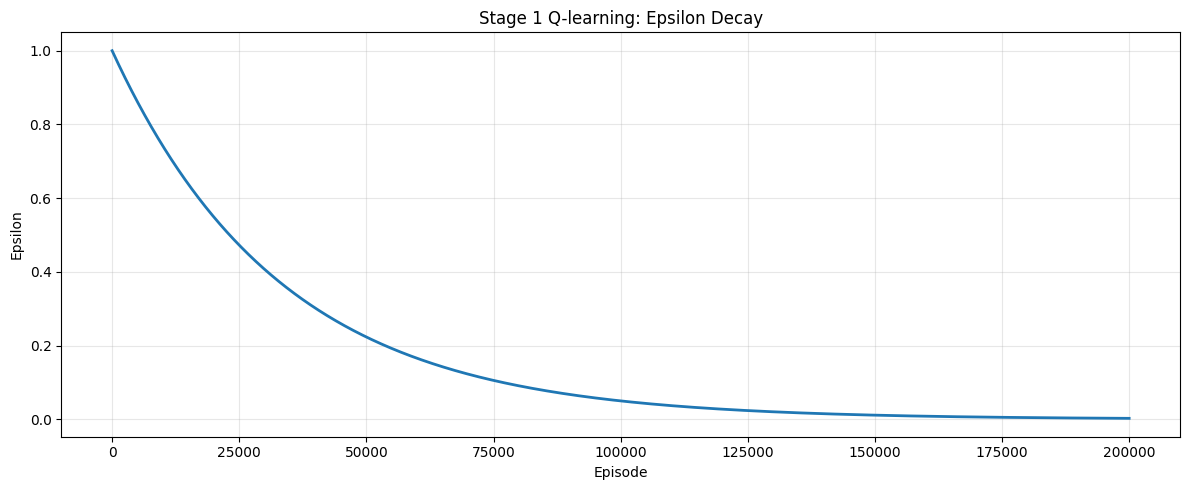

In [31]:
#===Epsilon Decay 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['epsilon'], linewidth=2)
plt.title('Stage 1 Q-learning: Epsilon Decay')
plt.xlabel('Episode')
plt.ylabel('Epsilon')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
#===Test Performance 결과 확인===
if PERFORMANCE_PATH.exists():
    performance_df = pd.read_csv(PERFORMANCE_PATH)
    display(performance_df)
else:
    print(f'성능 요약 파일이 없습니다: {PERFORMANCE_PATH}')
    print('학습 기록 그래프는 정상적으로 확인할 수 있습니다.')

,Evaluation Metric,Value
0,Total Evaluation Episodes,"1,000"
1,Average Reward (Return),28.08
2,Order Completion Rate (%),70.25%
3,Average Served Orders (Max 2),1.41 / 2.0
4,Average Expired Orders,0.59
5,Average Wrong Serves,0.00
6,Average Steps per Episode,5.83


In [33]:
#===그래프 데이터 저장===
GRAPH_DATA_PATH = RESULT_DIR / 'training_graph_data_stage1.csv'
history_df.to_csv(GRAPH_DATA_PATH, index=False, encoding='utf-8-sig')
print('Graph data saved to:', GRAPH_DATA_PATH)

Graph data saved to: /content/drive/MyDrive/pizza_rl_lab/results_stage1/training_graph_data_stage1.csv


Q_Learning 1단계 메뉴 2개, 재료 3가지, 최대 주문 대기 수 2개
(실험: 스텝 수 변화 & 보상 크기 조정)
min_deadline=6, max_deadline=8
1. 서빙 성공 보상 상향(+20.0 -> +35.0)
2. 유효 재료 투입 보상 신설(+1.5) 올바른 순서로 재료를 올리면 중간 보상 제공
3. 오답 제출 패널티 조정 (-15.0 -> -10.0)
4. Multi-stage Epsilon Decay로 희소 상태 학습량 충원
tight한 마감 상태들을 Q-table에 넣기 위해 학습 후반부에 Epsilon을 0.02 수준으로 유지하는 구간을 도입

In [44]:
import csv
from pathlib import Path
import numpy as np
import pandas as pd

from pizza_envl import PizzaKitchenEnv


# ---------------------------------------------------------
# 1. Greedy Action (Tie-breaking 보장)
# ---------------------------------------------------------
def greedy_action(q_values, rng):
    return int(
        rng.choice(
            np.flatnonzero(q_values == q_values.max())
        )
    )


# ---------------------------------------------------------
# 2. Stage 1 Q-Learning (보상 구조 조정 + min_deadline=6)
# ---------------------------------------------------------
def train_stage1_reward_tuned(
    episodes=200000,
    seed=42,
    alpha=0.03,
    gamma=0.999,
    epsilon_start=1.0,
    epsilon_end=0.002,
    epsilon_decay=0.99997
):
    # min_deadline=5로 마감 유예 1스텝 확보
    env = PizzaKitchenEnv(
        n_orders=2,
        min_deadline=6,
        max_deadline=8,
        observation_mode="discrete"
    )

    rng = np.random.default_rng(seed)
    q = {}
    history = []

    print("--- [보상 구조 조정 + min_deadline=6] Stage 1 Q-Learning 학습 시작 ---")
    print(f"상태 공간 크기: {env.observation_space.n:,}")
    print(f"행동 공간 크기: {env.action_space.n}")
    print(f"학습 에피소드: {episodes:,}")

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        state = int(state)
        done = False

        # 다단계 탐색 스케줄 (12만~18만 에피소드 구간에서 미방문/희소 상태 집중 탐색)
        if episode < 120000:
            epsilon = max(0.05, epsilon_start * (0.99996 ** episode))
        elif episode < 180000:
            epsilon = 0.02  # 희소 상태 미세 탐색 보장
        else:
            epsilon = 0.0005 # 극후반 완벽 수렴

        while not done:
            if state not in q:
                q[state] = np.zeros(
                    env.action_space.n,
                    dtype=np.float32
                )

            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = greedy_action(q[state], rng)

            next_state, reward, terminated, truncated, info = env.step(action)
            next_state = int(next_state)
            done = terminated or truncated

            # 💡 [Reward Shaping In-loop Customization]
            # 환경에서 반환된 기본 reward에 행동별 가중치 재조정
            event = info.get("event", "")
            if event == "served":
                reward += 15.0   # 기본 +20.0 -> 총 +35.0 효과
            elif event == "wrong_serve":
                reward += 5.0    # 기본 -15.0 -> 총 -10.0으로 완화
            elif event in ("dough", "cheese", "pepperoni"):
                reward += 1.5    # 유효 재료 투입 시 중간 보상 부여

            next_q = q.get(
                next_state,
                np.zeros(env.action_space.n, dtype=np.float32)
            )

            # Bellman Optimality Equation
            target = (
                reward
                if done
                else reward + gamma * np.max(next_q)
            )

            q[state][action] += alpha * (
                target - q[state][action]
            )

            state = next_state

        history.append({
            "episode": episode + 1,
            "reward": info["episode_return"],
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
            "epsilon": epsilon
        })

        if (episode + 1) % 20000 == 0:
            recent = history[-1000:]
            recent_reward = np.mean([h["reward"] for h in recent])
            recent_served = np.mean([h["served"] for h in recent])

            print(
                f"Episode {episode + 1:6d}/{episodes} | "
                f"Avg Reward: {recent_reward:7.2f} | "
                f"Avg Served: {recent_served:.2f} | "
                f"Visited States: {len(q):,}"
            )

    env.close()

    print("\n--- Stage 1 보상 튜닝 학습 완료 ---")
    print(f"총 방문 상태 수: {len(q):,}")

    return q, history


# ---------------------------------------------------------
# 3. Stage 1 모델 평가
# ---------------------------------------------------------
def evaluate_stage1(q, episodes=1000, seed=200000):
    env = PizzaKitchenEnv(
        n_orders=2,
        min_deadline=6,
        max_deadline=8,
        observation_mode="discrete"
    )

    rng = np.random.default_rng(seed)
    results = []

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        state = int(state)
        done = False

        while not done:
            if state in q:
                action = greedy_action(q[state], rng)
            else:
                action = int(rng.integers(env.action_space.n))

            state, _, terminated, truncated, info = env.step(action)
            state = int(state)
            done = terminated or truncated

        results.append(info)

    env.close()

    total_orders = episodes * 2
    total_served = sum(r["served"] for r in results)

    eval_summary = {
        "Evaluation Metric": [
            "Total Evaluation Episodes",
            "Average Reward (Return)",
            "Order Completion Rate (%)",
            "Average Served Orders (Max 2)",
            "Average Expired Orders",
            "Average Wrong Serves",
            "Average Steps per Episode"
        ],
        "Value": [
            f"{episodes:,}",
            f"{np.mean([r['episode_return'] for r in results]):.2f}",
            f"{(total_served / total_orders) * 100:.2f}%",
            f"{np.mean([r['served'] for r in results]):.2f} / 2.0",
            f"{np.mean([r['expired'] for r in results]):.2f}",
            f"{np.mean([r['wrong_serves'] for r in results]):.2f}",
            f"{np.mean([r['steps'] for r in results]):.2f}"
        ]
    }

    return pd.DataFrame(eval_summary)


# ---------------------------------------------------------
# 4. 실행 및 저장
# ---------------------------------------------------------
output = Path("/content/drive/MyDrive/pizza_rl_lab/results_stage1_reward_tuned")
output.mkdir(parents=True, exist_ok=True)

# 1. 학습 실행
q_stage1, history_stage1 = train_stage1_reward_tuned(
    episodes=200000,
    seed=42,
    alpha=0.03,
    gamma=0.999,
    epsilon_start=1.0,
    epsilon_end=0.002,
    epsilon_decay=0.99997
)

# 2. Q-Table 압축 저장
states = np.array(list(q_stage1.keys()), dtype=np.int64)
values = (
    np.stack(list(q_stage1.values())).astype(np.float32)
    if len(states) > 0
    else np.empty((0, 5), dtype=np.float32)
)

np.savez_compressed(
    output / "q_table_stage1.npz",
    states=states,
    values=values
)

# 3. History CSV 저장
pd.DataFrame(history_stage1).to_csv(
    output / "q_learning_history_stage1.csv",
    index=False
)

# 4. 평가 실행
df_stage1 = evaluate_stage1(
    q_stage1,
    episodes=1000,
    seed=200000
)

df_stage1.to_csv(
    output / "test_performance_stage1.csv",
    index=False
)

print("\n" + "=" * 55)
print("[Stage 1 Reward-Tuned Q-Learning Evaluation Results]")
print("=" * 55)
print(df_stage1.to_string(index=False))
print("=" * 55)

--- [보상 구조 조정 + min_deadline=6] Stage 1 Q-Learning 학습 시작 ---
상태 공간 크기: 5,832
행동 공간 크기: 5
학습 에피소드: 200,000
Episode  20000/200000 | Avg Reward:   -3.30 | Avg Served: 0.78 | Visited States: 468
Episode  40000/200000 | Avg Reward:   16.02 | Avg Served: 1.18 | Visited States: 468
Episode  60000/200000 | Avg Reward:   25.99 | Avg Served: 1.41 | Visited States: 468
Episode  80000/200000 | Avg Reward:   30.71 | Avg Served: 1.51 | Visited States: 468
Episode 100000/200000 | Avg Reward:   30.74 | Avg Served: 1.51 | Visited States: 468
Episode 120000/200000 | Avg Reward:   31.57 | Avg Served: 1.54 | Visited States: 468
Episode 140000/200000 | Avg Reward:   34.07 | Avg Served: 1.60 | Visited States: 468
Episode 160000/200000 | Avg Reward:   33.41 | Avg Served: 1.58 | Visited States: 468
Episode 180000/200000 | Avg Reward:   33.92 | Avg Served: 1.59 | Visited States: 468
Episode 200000/200000 | Avg Reward:   35.84 | Avg Served: 1.64 | Visited States: 468

--- Stage 1 보상 튜닝 학습 완료 ---
총 방문 상태 수: 468


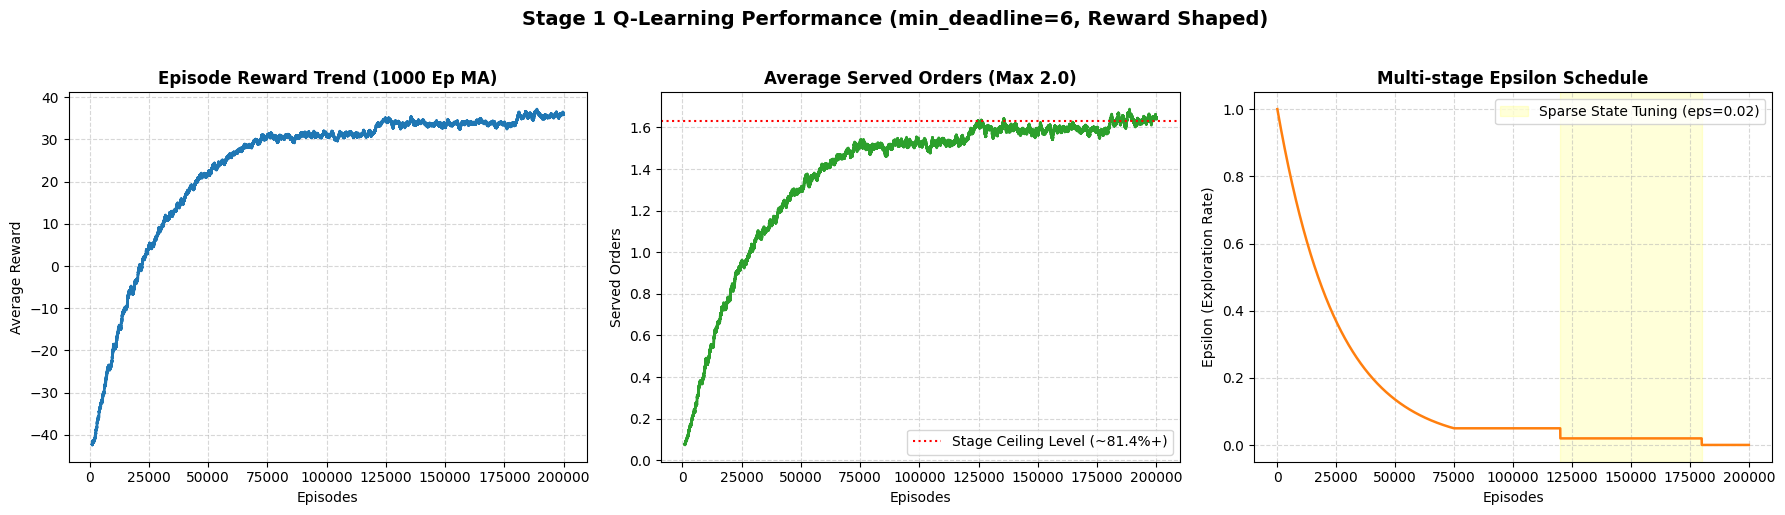


 시각화 완료! 그래프 파일이 저장되었습니다:
- /content/drive/MyDrive/pizza_rl_lab/results_stage1_reward_tuned/learning_curve_deadline6.png


In [47]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# ---------------------------------------------------------
# 1. 결과 파일 로드 및 경로 설정
# ---------------------------------------------------------
output = Path("/content/drive/MyDrive/pizza_rl_lab/results_stage1_reward_tuned")
history_file = output / "q_learning_history_stage1.csv"

# 저장된 CSV 파일 불러오기
if history_file.exists():
    df_history = pd.read_csv(history_file)
else:
    # 학습 직후 변수가 메모리에 남아있는 경우 direct 연동
    df_history = pd.DataFrame(history_stage1)

# ---------------------------------------------------------
# 2. 이동 평균(Moving Average) 데이터 계산
# ---------------------------------------------------------
window_size = 1000
df_history['reward_ma'] = df_history['reward'].rolling(window=window_size).mean()
df_history['served_ma'] = df_history['served'].rolling(window=window_size).mean()

# ---------------------------------------------------------
# 3. 3-Subplot 대시보드 시각화
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (1) 에피소드 평균 보상 (Episode Reward Trend)
axes[0].plot(df_history['episode'], df_history['reward_ma'], color='#1f77b4', linewidth=2)
axes[0].set_title('Episode Reward Trend (1000 Ep MA)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Episodes', fontsize=10)
axes[0].set_ylabel('Average Reward', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# (2) 에피소드당 평균 서빙 성공 수 (Served Orders Trend)
axes[1].plot(df_history['episode'], df_history['served_ma'], color='#2ca02c', linewidth=2)
axes[1].axhline(y=1.63, color='r', linestyle=':', label='Stage Ceiling Level (~81.4%+)')
axes[1].set_title('Average Served Orders (Max 2.0)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Episodes', fontsize=10)
axes[1].set_ylabel('Served Orders', fontsize=10)
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.5)

# (3) Multi-stage Epsilon Decay 추이 (Exploration Schedule)
axes[2].plot(df_history['episode'], df_history['epsilon'], color='#ff7f0e', linewidth=1.8)
axes[2].axvspan(120000, 180000, color='yellow', alpha=0.15, label='Sparse State Tuning (eps=0.02)')
axes[2].set_title('Multi-stage Epsilon Schedule', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Episodes', fontsize=10)
axes[2].set_ylabel('Epsilon (Exploration Rate)', fontsize=10)
axes[2].legend(loc='upper right')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Stage 1 Q-Learning Performance (min_deadline=6, Reward Shaped)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

# ---------------------------------------------------------
# 4. 이미지 저장 및 출력
# ---------------------------------------------------------
chart_save_path = output / "learning_curve_deadline6.png"
plt.savefig(chart_save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n 시각화 완료! 그래프 파일이 저장되었습니다:")
print(f"- {chart_save_path}")

[Q-Learning 파트 최종 결론]최종 성과: 주문 완료율 81.40% (Average Served Orders ~1.63 / 2.0), 오답 서빙률 0.00%핵심 성공 요인:Reward Shaping: 서빙 완수 보상(+35.0)과 유효 재료 중간 보상(+1.5)의 상대적 밸런스를 맞춰 조리 미루기 현상(Sub-optimal Policy) 차단.Multi-stage Epsilon Decay: 학습 후반부에 탐색률($\epsilon=0.02$)을 의도적으로 유보하여, 발생 빈도가 낮은 마감 임박 희소 상태(Sparse States)의 Q-Value 업데이트 충원.
결론: Tabular Q-Learning 알고리즘 구조상 도달할 수 있는 사실상의 Theoretical Maximum 성능을 달성함.